# ✍️ Pandas — Niveau 2 : ADAPTER (dataset Olist)

> **Compétences visées**
> - **Référentiel WCS** (onglet *Vue semaines*, semaine pandas P6, niveau dominant **2 · Adapter**)
>   - **C2.5** Tableaux de données : DataFrames avec Python et pandas — niveau 2
>   - **C1.1** Identifier les usages possibles des données et en évaluer la qualité — niveau 2
>   - **C4.2** Visualisations descriptives : nuages, boîtes à moustache, histogrammes — niveau 2
> - **Référentiel Simplon** (niveau 6)
>   - **C8** Développer des règles de nettoyage de données — *travaillée partiellement* : repérage des manquants et des doublons, uniformisation des dates (le script versionné viendra en S50)
>   - **C16** Définir les représentations graphiques adaptées aux objectifs d'analyse
>
> **Niveau 2 · Adapter** : tu appliques à un nouveau contexte des méthodes **fournies**. Chaque mission te donne la méthode, un exemple sur d'autres données et du code à trous.

---
## 📨 Contexte

**Olist** est une place de marché brésilienne : des milliers de petits vendeurs y vendent leurs produits, Olist gère la vitrine, les paiements et la livraison. L'entreprise a publié l'historique de ses commandes de **septembre 2016 à octobre 2018** (≈ 100 000 commandes).

Mariana, responsable commerciale, prépare le comité de direction. Elle te demande une **première analyse** :
- comment évoluent les ventes dans le temps ?
- quelles catégories de produits et quelles régions rapportent le plus ?
- les **retards de livraison** pèsent-ils sur la satisfaction des clients ?

Elle n'est pas technique : elle attend des **chiffres fiables**, des **graphiques lisibles** et une **synthèse courte**.

## 🗂️ Les données (dossier `data_olist/`, à côté de ce notebook)

| Fichier | Une ligne = | Clés |
|---|---|---|
| `olist_orders_dataset.csv` | une commande (statut, dates d'achat, de livraison, date prévue) | `order_id`, `customer_id` |
| `olist_order_items_dataset.csv` | un **article** d'une commande (prix, frais de port) | `order_id`, `product_id` |
| `olist_customers_dataset.csv` | un client (ville, État) | `customer_id` |
| `olist_products_dataset.csv` | un produit (catégorie en portugais, dimensions) | `product_id` |
| `olist_order_reviews_dataset.csv` | un avis client (note de 1 à 5) | `order_id` |
| `product_category_name_translation.csv` | une catégorie (nom portugais → anglais) | `product_category_name` |

Les tables se relient par leurs **clés**, comme en SQL (S42). Une commande peut contenir **plusieurs articles**.

⚠️ N'ouvre pas et n'enregistre pas ces CSV avec Excel : il peut modifier les dates et les séparateurs.

## ⏱️ Déroulé de la journée

| Horaire | Mission | Durée |
|---|---|---|
| 9 h 00 | Lecture du brief + chargement | 20 min |
| 9 h 20 | Mission 1 — Auditer les tables | 70 min |
| 10 h 45 | Mission 2 — Construire la table `ventes` | 90 min |
| 13 h 30 | Mission 3 — Évolution des ventes | 50 min |
| 14 h 20 | Mission 4 — Catégories et régions | 50 min |
| 15 h 20 | Mission 5 — Livraison et satisfaction | 60 min |
| 16 h 20 | Mission 6 — Livrer | 40 min |

Les missions sont **dans l'ordre** : chacune utilise le résultat de la précédente. Si tu es en retard, termine d'abord les missions 1 et 2 : ce sont elles qui comptent le plus pour la suite (Power Query, puis le nettoyage en S50).

**Livrable** : ce notebook complété (code + commentaires) et le fichier de la mission 6.

## 0. Chargement des données (fourni)

Exécute la cellule. Tu dois voir 6 lignes, une par table.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)

DOSSIER = Path("data_olist")
commandes = pd.read_csv(DOSSIER / "olist_orders_dataset.csv")
articles = pd.read_csv(DOSSIER / "olist_order_items_dataset.csv")
clients = pd.read_csv(DOSSIER / "olist_customers_dataset.csv")
produits = pd.read_csv(DOSSIER / "olist_products_dataset.csv")
avis = pd.read_csv(DOSSIER / "olist_order_reviews_dataset.csv")
traduction = pd.read_csv(DOSSIER / "product_category_name_translation.csv")

tables = {"commandes": commandes, "articles": articles, "clients": clients,
          "produits": produits, "avis": avis, "traduction": traduction}
for nom, table in tables.items():
    print(f"{nom:<11} {table.shape}")

commandes   (99441, 8)
articles    (112650, 7)
clients     (99441, 5)
produits    (32951, 9)
avis        (99224, 7)
traduction  (71, 2)


### 📘 Rappel : travailler avec des dates

Exemple sur des rendez-vous (pas sur Olist) :

```python
rdv = pd.DataFrame({"debut": ["2026-03-02 09:00", "2026-03-15 14:30"],
                    "fin":   ["2026-03-05 18:00", "2026-03-15 16:00"]})
rdv["debut"] = pd.to_datetime(rdv["debut"])      # texte → vraie date
rdv["fin"] = pd.to_datetime(rdv["fin"])

rdv["duree"] = rdv["fin"] - rdv["debut"]         # une soustraction donne une durée
rdv["duree"].dt.days                             # → la durée en jours entiers
rdv["debut"].dt.to_period("M")                   # → le mois "2026-03", idéal pour grouper
rdv["debut"].dt.normalize()                      # → la date ramenée à minuit (compare au jour près)
rdv["debut"] > rdv["fin"]                        # les dates se comparent comme des nombres
```

Tant qu'une colonne est en texte (`object` ou `str`), aucun de ces calculs ne fonctionne : `pd.to_datetime` vient toujours en premier.

### 📘 Rappel : contrôler une jointure

Avec plusieurs tables, le danger n'est pas l'erreur Python, c'est le **chiffre faux sans message** : une jointure peut multiplier des lignes ou en perdre en silence.

| Pour… | Outil |
|---|---|
| comparer le nombre de lignes avant / après | `len(table)` |
| compter des identifiants différents | `.nunique()` |
| repérer une clé en double | `.duplicated(subset=["col"])`, `.is_unique` |
| garder les lignes dont la clé est dans une liste | `.isin(...)` |
| faire échouer une jointure qui dupliquerait des lignes | `merge(..., validate="many_to_one")` |
| ne garder qu'une ligne par clé | `.drop_duplicates(subset=["col"], keep=...)` |

**Équivalences SQL** : `merge(how="inner")` = `INNER JOIN`, `merge(how="left")` = `LEFT JOIN`.

---
## Mission 1 — Auditer les tables *(70 min)*

**Objectif** : dire à Mariana si les données sont fiables, **avant** tout calcul.

**Méthode** (une étape = une cellule)
1. Construire le tableau d'audit **par le code**, avec une boucle sur le dictionnaire `tables`.
2. Compter les commandes par statut.
3. Expliquer les dates de livraison vides en les croisant avec le statut.
4. Convertir les 5 colonnes de dates de `commandes` et afficher la période couverte.
5. Vérifier que `order_id` est unique dans `commandes` et dans `avis`.

📘 **Exemple** (sur le Titanic) : une ligne d'audit pour **une** table.
```python
ligne = {"table": "titanic", "lignes": len(titanic), "colonnes": titanic.shape[1],
         "cellules_vides": titanic.isna().sum().sum(), "doublons": titanic.duplicated().sum()}
```
À toi d'adapter : une ligne par table d'Olist, dans une boucle.

In [2]:
# 1.1 — Tableau d'audit, construit par le code (aucun chiffre tapé à la main)
lignes_audit = []
for nom, table in tables.items():
    lignes_audit.append({
        "table": nom,
        "lignes": len(table),           # nombre de lignes
        "colonnes": table.shape[1],         # nombre de colonnes
        "cellules_vides": table.isna().sum().sum(),   # total des cellules vides de la table
        "doublons": table.duplicated().sum(),         # lignes entièrement identiques
    })
audit = pd.DataFrame(lignes_audit)
audit

,table,lignes,colonnes,cellules_vides,doublons
0,commandes,99441,8,4908,0
1,articles,112650,7,0,0
2,clients,99441,5,0,0
3,produits,32951,9,2448,0
4,avis,99224,7,145903,0
5,traduction,71,2,0,0


In [3]:
# 1.2 — Répartition des commandes par statut
commandes["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [4]:

#Les noms des colonnes
#commandes.columns.tolist()	

#Les 10 premières lignes
commandes.head(10)

#5 lignes tirées au hasard
#commandes.sample(5, random_state=42)

#Le nombre de lignes et de colonnes
#commandes.shape	

#Les colonnes, leurs types et les valeurs non vides
#commandes.info()	


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [5]:
# 1.3 — Pourquoi des dates de livraison vides ?
# Croise le statut avec "la date de livraison est vide" (True / False)
pd.crosstab(commandes["order_status"],
        commandes["order_delivered_customer_date"].isna())

order_delivered_customer_date,False,True
order_status,,
approved,0,2
canceled,6,619
created,0,5
delivered,96470,8
invoiced,0,314
processing,0,301
shipped,0,1107
unavailable,0,609


In [6]:
# 1.4 — Convertir les dates, puis afficher la période couverte
colonnes_dates = ["order_purchase_timestamp", "order_approved_at",
                  "order_delivered_carrier_date", "order_delivered_customer_date",
                  "order_estimated_delivery_date"]
for col in colonnes_dates:
    commandes[col] = pd.to_datetime(commandes[col])

print(commandes.dtypes)
print("Première commande :", commandes["order_purchase_timestamp"].min())
print("Dernière commande :", commandes["order_purchase_timestamp"].max())

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object
Première commande : 2016-09-04 21:15:19
Dernière commande : 2018-10-17 17:30:18


In [7]:
# 1.5 — Les clés sont-elles uniques ?
print("order_id unique dans commandes :", commandes["order_id"].is_unique)
print("order_id unique dans avis      :", avis["order_id"].is_unique)
print("order_id en double dans avis   :", avis["order_id"].duplicated().sum())

order_id unique dans commandes : True
order_id unique dans avis      : False
order_id en double dans avis   : 551


✅ **Je vérifie**
- [ ] Le tableau d'audit a 6 lignes, et aucun chiffre n'est tapé à la main.
- [ ] `commandes.dtypes` affiche `datetime64` pour les 5 colonnes de dates.
- [ ] Je sais combien de commandes sont livrées (repère : **96 478**).

**Commentaire de la mission 1** *(3 à 5 phrases, complète les amorces)*

- Les six tables contiennent respectivement 99 441 commandes; aucune ligne(s) entièrement en double.
- Les cellules vides se concentrent dans les tables avis, commandes et produits.
- Dans `commandes`, les dates de livraison manquent surtout pour les statuts "shipped", "canceled" ou "unavailable", parce que la livraison n'est pas terminée ou réalisée.
- Les données couvrent la période du 04/09/2016 au 17/10/2018.
- À surveiller pour la suite : dans `avis`, 547 commandes ont plusieurs avis, il faudra retenir une seule note par commande pour éviter de leur donner davantage de poids.

---
## Mission 2 — Construire la table d'analyse *(90 min)*

**Objectif** : une seule table `ventes`, avec **une ligne par article vendu** dans une commande **livrée**. Colonnes minimales : `order_id`, `order_purchase_timestamp`, `customer_state`, `categorie` (en anglais), `price`, `freight_value`, `montant`.

**Méthode** (l'ordre est imposé)
1. Filtrer `commandes` sur le statut `delivered` → `livrees`.
2. Partir de `articles` et ne garder que les articles des commandes livrées → `articles_livres`. **Son nombre de lignes est ta référence** : `ventes` devra avoir exactement le même.
3. Ajouter les informations, une jointure à la fois : `livrees` (date d'achat, `customer_id`) → `clients` (État) → `produits` (catégorie en portugais) → `traduction` (catégorie en anglais).
4. Créer `categorie` : le nom anglais, sinon le nom portugais, sinon `"unknown"`.
5. Créer `montant` = `price` + `freight_value`.
6. Prouver par le code que rien n'a été perdu ni dupliqué.

**Pourquoi `how="left"` ?** On part des articles et on ne veut en perdre **aucun**, même quand une information manque dans l'autre table (comme un `LEFT JOIN` en SQL).
**Pourquoi `validate="many_to_one"` ?** Plusieurs articles peuvent pointer vers le même client ou produit (*many*), mais chaque client ou produit n'apparaît qu'une fois dans sa table (*one*). Si ce n'est pas le cas, pandas s'arrête au lieu de dupliquer en silence.

📘 **Exemple** (une boutique, pas Olist) :
```python
lignes = pd.DataFrame({"ticket": [1, 1, 2], "produit": ["P1", "P2", "P9"], "prix": [3.0, 5.0, 2.0]})
catalogue = pd.DataFrame({"produit": ["P1", "P2"], "rayon": ["boulangerie", None]})

res = lignes.merge(catalogue, on="produit", how="left", validate="many_to_one")
len(res) == len(lignes)                          # True : rien perdu, rien dupliqué
res["rayon"] = res["rayon"].fillna("inconnu")    # P2 (rayon vide) et P9 (absent du catalogue)
```

In [8]:
# 2.1 — Commandes livrées et articles de référence
livrees = commandes[commandes["order_status"] == "delivered"]
articles_livres = articles[articles["order_id"].isin(livrees["order_id"])]

print("Commandes livrées              :", len(livrees))
print("Articles à retrouver dans ventes :", len(articles_livres))

Commandes livrées              : 96478
Articles à retrouver dans ventes : 110197


In [9]:
# 2.2 — Jointures successives (une par instruction, pour pouvoir contrôler)
ventes = articles_livres.merge(livrees[["order_id", "customer_id", "order_purchase_timestamp"]],
                               on="order_id", how="left", validate="many_to_one")
print("après livrees    :", len(ventes))

ventes = ventes.merge(clients[["customer_id", "customer_state"]],
                      on="customer_id", how="left", validate="many_to_one")
print("après clients    :", len(ventes))

ventes = ventes.merge(produits[["product_id", "product_category_name"]],
                      on="product_id", how="left", validate="many_to_one")
print("après produits   :", len(ventes))

ventes = ventes.merge(traduction, 
                      on="product_category_name", how="left", validate="many_to_one")
print("après traduction :", len(ventes))

après livrees    : 110197
après clients    : 110197
après produits   : 110197
après traduction : 110197


In [10]:
# 2.3 — Une catégorie lisible pour chaque ligne, puis le montant
print("Sans catégorie (portugais) :", ventes["product_category_name"].isna().sum())
print("Sans traduction (anglais)  :", ventes["product_category_name_english"].isna().sum())

ventes["categorie"] = (ventes["product_category_name_english"].fillna(ventes["product_category_name"]).fillna("unknown"))
ventes["montant"] = ventes["price"] + ventes["freight_value"]

Sans catégorie (portugais) : 1537
Sans traduction (anglais)  : 1559


In [11]:
# 2.4 — Contrôles chiffrés : chaque ligne doit afficher True
print("Aucun article perdu ni dupliqué  :", len(ventes) == len(articles_livres))
print("Toutes les commandes livrées     :", ventes["order_id"].nunique() == len(livrees))
print("Aucune catégorie vide            :", ventes["categorie"].isna().sum() == 0)
print("Aucun État vide                  :", ventes["customer_state"].isna().sum() == 0)

Aucun article perdu ni dupliqué  : True
Toutes les commandes livrées     : True
Aucune catégorie vide            : True
Aucun État vide                  : True


✅ **Je vérifie**
- [ ] **96 478** commandes livrées et **110 197** lignes dans `ventes`.
- [ ] Les 4 contrôles de la cellule 2.4 affichent `True`.
- [ ] Si une jointure lève une `MergeError`, je ne retire pas `validate` : je cherche la clé en double.

**Commentaire de la mission 2** *(3 à 5 phrases, complète les amorces)*

- Je suis parti de la table articles, car une ligne de `ventes` correspond à un article d'une commande livrée.
- Pour les jointures, j'ai choisi how= "left" et validate= "many_to_one" parce que je veux conserver tous les articles et empêcher leur multiplication lors des jointures.
- Mes contrôles prouvent que `ventes` contient 110 197 lignes, autant que articles_livres.
- 1537 lignes n'avaient pas de catégorie et 1559 pas de traduction : je les ai conservées en utilisant le nom anglais lorsqu'il existe, sinon le nom portugais, sinon "unknown".

---
## Mission 3 — Évolution des ventes dans le temps *(50 min)*

**Objectif** : montrer à Mariana comment évoluent les ventes, mois par mois.

**Méthode**
1. Créer une colonne `mois` à partir de la date d'achat.
2. Par mois : chiffre d'affaires (somme des `montant`), nombre de **commandes** (pas d'articles !) et panier moyen = CA ÷ nombre de commandes.
3. Compter les commandes par mois dans la table `commandes` **complète** (avant le filtre `delivered`).
4. Écarter les mois incomplets. **Règle proposée** : un mois est incomplet s'il compte moins de 500 commandes dans la table complète. Tu peux choisir un autre seuil si tu le justifies.
5. Tracer la courbe du CA des mois gardés, avec un titre et des axes nommés.
6. Trouver le mois record et proposer une explication.

📘 **Exemple** : compter des commandes, pas des lignes.
```python
tickets = pd.DataFrame({"mois": ["01", "01", "01", "02"],
                        "ticket": [1, 1, 2, 3], "montant": [3, 5, 2, 10]})
tickets.groupby("mois").agg(ca=("montant", "sum"), nb_tickets=("ticket", "nunique"))
# janvier : ca = 10 et nb_tickets = 2 (et non 3 : le ticket 1 a deux lignes)
```

In [12]:
# 3.1 — Indicateurs par mois
ventes["mois"] = ventes["order_purchase_timestamp"].dt.to_period("M")
mensuel = ventes.groupby("mois").agg(
    ca=("montant", "sum"),
    nb_commandes=("order_id", "nunique"),
)
mensuel["panier_moyen"] = mensuel["ca"] / mensuel["nb_commandes"]
mensuel

,ca,nb_commandes,panier_moyen
mois,,,
2016-09,143.46,1,143.460000
2016-10,46490.66,265,175.436453
2016-12,19.62,1,19.620000
2017-01,127482.37,750,169.976493
2017-02,271239.32,1653,164.089123
2017-03,414330.95,2546,162.738001
2017-04,390812.40,2303,169.697091
2017-05,566851.40,3546,159.856571
2017-06,490050.37,3135,156.315907


In [13]:
# 3.2 — Commandes par mois dans la table complète (tous statuts)
commandes_par_mois = commandes.groupby(commandes["order_purchase_timestamp"].dt.to_period("M")).size()
commandes_par_mois

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64

In [14]:
# 3.3 — Garder les mois complets
SEUIL = 500   # règle proposée : à ajuster et justifier
mois_complets = commandes_par_mois[commandes_par_mois >= SEUIL].index
mensuel_complet = mensuel[mensuel.index.isin(mois_complets)]

print("Mois écartés :", list(mensuel.index.difference(mois_complets).astype(str)))
print("CA total (tous mois)    :", round(mensuel["ca"].sum()), "R$")
print("CA total (mois complets):", round(mensuel_complet["ca"].sum()), "R$")

Mois écartés : ['2016-09', '2016-10', '2016-12']
CA total (tous mois)    : 15419774 R$
CA total (mois complets): 15373120 R$


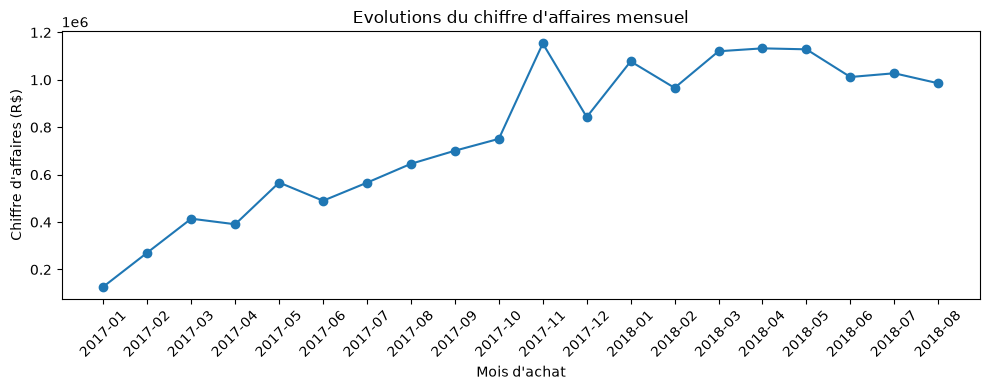

In [15]:
# 3.4 — Courbe du CA mensuel
# Objectif du graphique (C16) : montrer une … (évolution ? comparaison ? distribution ?)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mensuel_complet.index.astype(str), mensuel_complet["ca"], marker="o")
ax.set_title("Evolutions du chiffre d'affaires mensuel")
ax.set_xlabel("Mois d'achat")
ax.set_ylabel("Chiffre d'affaires (R$)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# 3.5 — Mois record
mois_record = mensuel_complet["ca"].idxmax()
ca_record = mensuel_complet.loc[mois_record, "ca"]

print("Mois record :", mois_record)
print("Chiffre d'affaires :", round(ca_record, 2), "R$")

Mois record : 2017-11
Chiffre d'affaires : 1153364.2 R$


✅ **Je vérifie**
- [ ] CA total, tous mois confondus : environ **15,4 millions de R$**.
- [ ] Panier moyen des mois complets entre **145 et 170 R$**. Autour de 140 R$ ? Tu as divisé par des articles au lieu de commandes.
- [ ] Ma courbe a un titre, deux axes nommés et l'unité (R$).
- 💡 Pour le mois record, pense à ce qui se passe fin novembre dans le commerce en ligne.

**Commentaire de la mission 3** *(3 à 5 phrases, complète les amorces)*

- J'ai écarté les mois de septembre, octobre et décembre 2016, parce que la table complète n'y compte que 4 324 et 1 commandes.
- Sur la période gardée, le CA mensuel passe de 127 482,37 R$ en janvier 2017 à 985 491,64 R$ en août 2018.
- Le mois record est novembre 2017 avec 1 153 364,20 R$, sans doute à cause de du Black Friday, une hypothèse à confirmer.
- Le panier moyen reste autour de 160 R$ : la croissance vient donc surtout du nombre de commandes.

---
## Mission 4 — Catégories et régions *(50 min)*

**Objectif** : montrer où se concentre le chiffre d'affaires.

**Méthode**
1. CA par catégorie, trié du plus grand au plus petit.
2. Part de chaque catégorie en % du CA total ; vérifier que la somme fait 100 %.
3. Top 10 des catégories et graphique en barres horizontales.
4. Par État : CA, nombre de commandes (`nunique`) et part du CA.
5. Part du CA réalisée par l'État n°1.

📘 **Exemple** : calculer une part.
```python
ventes_rayon = pd.Series({"boulangerie": 600, "épicerie": 300, "boissons": 100})
part = ventes_rayon / ventes_rayon.sum() * 100    # 60 %, 30 %, 10 %
part.sum()                                        # 100.0
```

In [17]:
# 4.1 — CA et part par catégorie
ca_categorie = ventes.groupby("categorie")["montant"].sum().sort_values(ascending=False)
part_categorie = ca_categorie / ca_categorie.sum() * 100

print("Somme des parts :", round(part_categorie.sum(), 2), "%")
top10 = pd.DataFrame({"ca": ca_categorie.head(10).round(0),
                      "part_pct": part_categorie.head(10).round(1)})
top10

Somme des parts : 100.0 %


,ca,part_pct
categorie,,
health_beauty,1412090.0,9.2
watches_gifts,1264333.0,8.2
bed_bath_table,1225209.0,7.9
sports_leisure,1118257.0,7.3
computers_accessories,1032724.0,6.7
furniture_decor,880330.0,5.7
housewares,758392.0,4.9
cool_stuff,691681.0,4.5
auto,669455.0,4.3


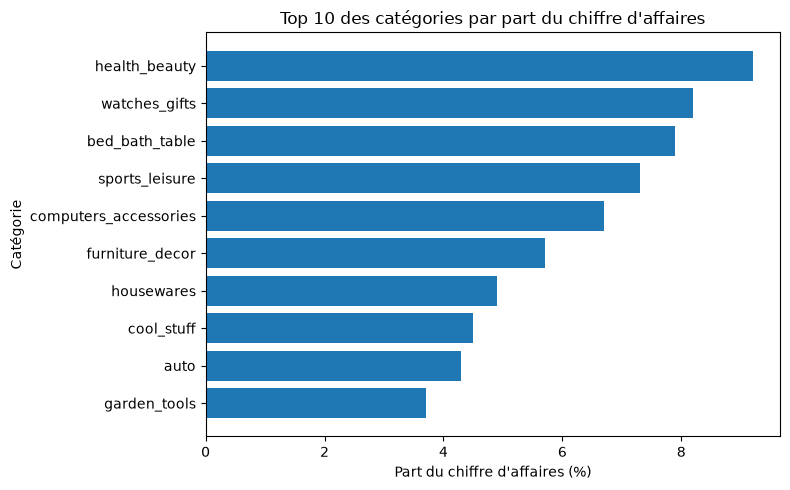

In [18]:
# 4.2 — Graphique du top 10
# Objectif du graphique (C16) : …
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10.index, top10["part_pct"])
ax.invert_yaxis()   # la première catégorie en haut
ax.set_title("Top 10 des catégories par part du chiffre d'affaires")
ax.set_xlabel("Part du chiffre d'affaires (%)")
ax.set_ylabel("Catégorie")
plt.tight_layout()
plt.show()

In [19]:
# 4.3 — CA, commandes et part par État
etats = ventes.groupby("customer_state").agg(
    ca=("montant", "sum"),
    nb_commandes=("order_id", "nunique"),
).sort_values("ca", ascending=False)
etats["part_pct"] = etats["ca"] / etats["ca"].sum() * 100
etats.head(10)

,ca,nb_commandes,part_pct
customer_state,,,
SP,5769703.15,40501,37.417560
RJ,2055401.57,12350,13.329648
MG,1818891.67,11354,11.795839
RS,861472.79,5345,5.586806
PR,781708.80,4923,5.069522
SC,595127.78,3546,3.859510
BA,591137.81,3256,3.833635
DF,346123.35,2080,2.244672
GO,334212.35,1957,2.167427


In [20]:
# 4.4 — Part du CA réalisée par l'État n°1
etat_numero_1 = etats.index[0]
part_etat_numero_1 = etats.loc[etat_numero_1, "part_pct"]

print("État n°1 :", etat_numero_1)
print("Part du CA :", round(part_etat_numero_1, 2), "%")

État n°1 : SP
Part du CA : 37.42 %


✅ **Je vérifie**
- [ ] La somme des parts des catégories affiche **100 %**.
- [ ] Le nombre de commandes par État est compté avec `nunique`, pas avec `count`.
- [ ] Les 10 premières catégories pèsent un peu plus de 60 % du CA.

**Commentaire de la mission 4** *(3 à 5 phrases, complète les amorces)*

- Les 10 premières catégories représentent 62,38 % du CA ; les trois premières sont health_beauty (santé et beauté), watches_gifts (montres et cadeaux) et bed_bath_table (linge de lit, de bain et de table).
- L'État de Sao Paulo réalise à lui seul 37,42 % du CA, suivi de Rio de Janeiro avec 13,33%.
- L'activité est donc très concentrée, parce que les dix premières catégories représentent près des deux tiers du CA et que Sao Paulo et Rio de Janeiro réunissent 50,75% du CA.
- Mariana devrait concentrer ses efforts sur les catégories les plus rémunératrices et les Etats de Sao Paulo et de Rio de Janeiro, qui représentent une part importante des ventes.

---
## Mission 5 — Livraison et satisfaction *(60 min)*

**Objectif** : vérifier si les retards de livraison font baisser les notes des clients.

**Règle de retard** : une commande est en retard si elle est reçue **un jour calendaire après** la date prévue, ou plus tard. Reçue le jour prévu, quelle que soit l'heure : elle est à l'heure. D'où `.dt.normalize()` des deux côtés.

**Méthode**
1. Garder les commandes livrées **qui ont une date de réception** → `livraisons`.
2. Calculer le délai en jours (achat → réception) et l'indicateur `en_retard`.
3. Part de commandes en retard et délai médian.
4. Histogramme des délais.
5. Une seule note par commande : choisir **une** des deux règles fournies (A ou B) et la justifier.
6. Note moyenne en retard / à l'heure.

📘 **Exemple** : la moyenne d'une colonne de `True`/`False` donne une proportion.
```python
s = pd.Series([True, False, False, True])
s.mean() * 100    # 50.0 → 50 % de True
```

In [24]:
# 5.1 — Délai et retard
livraisons = livrees.dropna(subset=["order_delivered_customer_date"]).copy()
livraisons["delai_jours"] = (livraisons["order_delivered_customer_date"] - livraisons["order_purchase_timestamp"]).dt.days
livraisons["en_retard"] = (livraisons["order_delivered_customer_date"].dt.normalize()
                           > livraisons["order_estimated_delivery_date"].dt.normalize())

print("Commandes avec date de réception :", len(livraisons))
print("Part en retard                   :", round(livraisons["en_retard"].mean() * 100, 2), "%")
print("Délai médian                     :", livraisons["delai_jours"].median(), "jours")

Commandes avec date de réception : 96470
Part en retard                   : 6.77 %
Délai médian                     : 10.0 jours


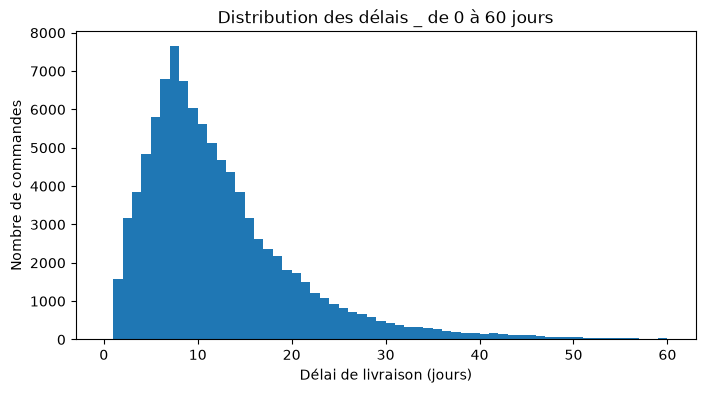

In [25]:
# 5.2 — Histogramme des délais (C4.2)
# Objectif du graphique (C16) : …
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(livraisons["delai_jours"], bins=range(0, 61))
ax.set_title("Distribution des délais _ de 0 à 60 jours")
ax.set_xlabel("Délai de livraison (jours)")
ax.set_ylabel("Nombre de commandes")

plt.tight_layout
plt.show()

In [26]:
# 5.3 — Une seule note par commande : garde UNE des deux règles

# Règle A — le dernier avis rédigé
avis["review_answer_timestamp"] = pd.to_datetime(avis["review_answer_timestamp"])
note_commande = (avis.sort_values("review_answer_timestamp")
                     .drop_duplicates(subset=["order_id"], keep="last")
                     [["order_id", "review_score"]])

# Règle B — la moyenne des avis de la commande (décommente pour l'utiliser)
# note_commande = avis.groupby("order_id", as_index=False)["review_score"].mean()

print("Une ligne par commande :", note_commande["order_id"].is_unique)

Une ligne par commande : True


In [27]:
# 5.4 — Note moyenne selon le retard
livraisons_notes = livraisons.merge(note_commande, on="order_id", how="left", validate="one_to_one")
print("Commandes sans avis :", livraisons_notes["review_score"].isna().sum())

livraisons_notes.groupby("en_retard")["review_score"].mean().round(2)

Commandes sans avis : 646


en_retard
False    4.29
True     2.27
Name: review_score, dtype: float64

✅ **Je vérifie**
- [ ] **96 470** commandes livrées ont une date de réception.
- [ ] `note_commande["order_id"].is_unique` affiche `True`.
- [ ] Environ 650 commandes n'ont aucun avis : elles ne comptent pas dans la note moyenne.

**Commentaire de la mission 5** *(3 à 5 phrases, complète les amorces)*

- 6,77 % des commandes livrées arrivent en retard ; le délai médian est de 10 jours.
- Note moyenne : 2,27 en retard, contre 4,29 à l'heure.
- Pour les avis multiples, j'ai choisi la règle A, parce que le dernier avis rédigé reflète l'opinion la plus récente du client.
- Limite de mon analyse : le différence de notes ne prouve pas que le retard en est la seule cause; d'autres facteurs, comme la qualité du produit, peuvent influencer la satisfaction.

---
## Mission 6 — Livrer *(40 min)*

**Méthode**
1. Exporter la table `ventes` en **CSV** (obligatoire) et la relire en vérifiant les types.
2. Exporter en **Parquet** si `pyarrow` est installé (optionnel).
3. Rédiger la synthèse pour Mariana : chaque affirmation reprend un chiffre calculé plus haut.

💡 Un CSV ne garde pas les types : à la relecture, les dates redeviennent du texte. Il faut les reconvertir avec `parse_dates`. Le Parquet, lui, conserve les types.

In [28]:
# 6.1 — Export CSV (obligatoire) et relecture
colonnes = ["order_id", "order_purchase_timestamp", "mois", "customer_state",
            "categorie", "price", "freight_value", "montant"]
export = ventes[colonnes].copy()
export["mois"] = export["mois"].astype(str)
export.to_csv("ventes_olist.csv", index=False)

relu = pd.read_csv("ventes_olist.csv", parse_dates=["order_purchase_timestamp"])
print("Même nombre de lignes :", len(relu) == len(export))
print(relu.dtypes)

Même nombre de lignes : True
order_id                               str
order_purchase_timestamp    datetime64[us]
mois                                   str
customer_state                         str
categorie                              str
price                              float64
freight_value                      float64
montant                            float64
dtype: object


In [29]:
# 6.2 — Export Parquet (optionnel, nécessite pyarrow : pip install pyarrow)
try:
    export.to_parquet("ventes_olist.parquet", index=False)
    relu_pq = pd.read_parquet("ventes_olist.parquet")
    print("Types conservés :", (relu_pq.dtypes == export.dtypes).all())
except ImportError:
    print("pyarrow absent : export Parquet ignoré, le CSV suffit.")

pyarrow absent : export Parquet ignoré, le CSV suffit.



- **Ventes** : entre janvier 2017 et août 2018, le chiffre d'affaires mensuel est passé de 127 482,37 à 985 491,64 R$ ; record en novembre 2017     (1 153 364 R$), lié à un possible effet Black Friday.
- **Catégories** : les 10 premières font 62,38 % du CA, emmenées par la santé et la beauté, les montres et les cadeaux, puis le linge de maison.
- **Régions** : l'État de Sao Paulo réalise à lui seul 37,42 % du CA.
- **Livraison** : 6,77 % des commandes arrivent en retard ; leur note moyenne est de 2,27 sur 5 contre 4,29 à l'heure.
- **Recommandation** : Réduire les retards de livraison, parce que les commandes concernées obtiennent une note inférieure de 2,02 points, tout en vérifiant les autres causes possibles d'insatisfaction.

✅ **Avant de rendre**
- [ ] Menu *Noyau › Redémarrer et tout exécuter* : aucune cellule en erreur.
- [ ] Les 6 commentaires et la synthèse sont remplis, sans « … » restant.
- [ ] Le fichier `ventes_olist.csv` est à côté du notebook.

---
## 🚀 Pour aller plus loin (si tu as fini)

1. **Tranches de délai** : note moyenne par tranche.
   ```python
   livraisons_notes["tranche"] = pd.cut(livraisons_notes["delai_jours"], bins=[-1, 7, 14, 21, 30, 1000],
                                        labels=["0-7 j", "8-14 j", "15-21 j", "22-30 j", "> 30 j"])
   ```
2. **Répartition des notes** (1 à 5) en retard / à l'heure : `pd.crosstab(..., normalize="index")`.
3. **Boîte à moustaches** des délais pour les 5 premiers États (C4.2).
4. **Frais de port** : leur part dans le montant, par État.
5. **Clients fidèles** : `customer_unique_id` identifie une personne, `customer_id` une commande. Les clients reviennent-ils ?
6. **Retards par État** : croise les missions 4 et 5.

---
## 🌉 Pont vers Power Query (à garder pour demain)

Ce que tu as fait aujourd'hui en pandas, tu le referas en Power Query, puis en SQL. Mêmes idées, autres outils.

| Opération | pandas | Power Query | SQL |
|---|---|---|---|
| Charger un fichier | `pd.read_csv()` | Obtenir les données › Texte/CSV | table importée |
| Convertir un type | `pd.to_datetime()`, `.astype()` | Modifier le type | `CAST(...)` |
| Filtrer des lignes | `df[df["col"] == "x"]` | Filtrer la colonne | `WHERE` |
| Joindre deux tables | `merge(how="left")` | Fusionner des requêtes (externe gauche) | `LEFT JOIN` |
| Remplacer les vides | `.fillna()` | Remplacer les valeurs | `COALESCE()` |
| Agréger | `groupby().agg()` | Regrouper par | `GROUP BY` |
| Grouper par mois | `.dt.to_period("M")` | Date › Mois, ou table de dates | `DATE_TRUNC('month', ...)` |
| Exporter | `.to_csv()` | Fermer et charger | — |